# Question 1 — Sunflower Blob Detection using LoG



In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

SIGMA_MIN = 1.5
SIGMA_MAX = 18.0
NUM_SCALES = 24
RESPONSE_THRESHOLD = 0.035  # Adjust after inspecting results
NMS_XY_RADIUS = 8
MAX_DETECTIONS = 250

(np.float64(-0.5), np.float64(359.5), np.float64(359.5), np.float64(-0.5))

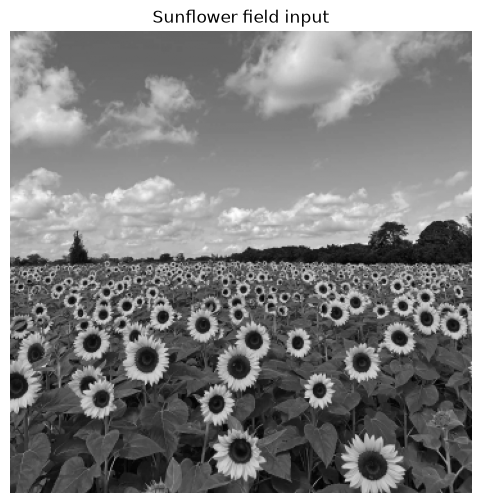

In [2]:
color = cv2.imread(r"a2images\the_berry_farms_sunflower_field.jpeg", cv2.IMREAD_REDUCED_COLOR_4)
assert color is not None
gray = cv2.cvtColor(color, cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(10, 6))
plt.imshow(gray, cmap="gray")
plt.title("Sunflower field input")
plt.axis("off")


In [3]:
def detect_log_blobs(gray):
    gray_f = gray.astype(np.float32) / 255.0
    sigmas = np.geomspace(SIGMA_MIN, SIGMA_MAX, NUM_SCALES)
    responses = []

    for sigma in sigmas:
        blurred = cv2.GaussianBlur(
            gray_f, (0, 0), sigmaX=float(sigma), sigmaY=float(sigma),
            borderType=cv2.BORDER_REFLECT
        )
        lap = cv2.Laplacian(blurred, cv2.CV_32F, ksize=3)
        responses.append((float(sigma) ** 2) * np.abs(lap))

    volume = np.stack(responses, axis=0)  # (scale, y, x)
    local_max = maximum_filter(volume, size=(3, 3, 3), mode="nearest")
    maxima = (volume == local_max) & (volume >= RESPONSE_THRESHOLD)

    coords = np.argwhere(maxima)
    candidates = [
        (int(x), int(y), float(sigmas[si]), float(volume[si, y, x]))
        for si, y, x in coords
    ]
    candidates.sort(key=lambda item: item[3], reverse=True)

    kept = []
    for detection in candidates:
        x, y, sigma, response = detection
        if all((x-kx)**2 + (y-ky)**2 >= NMS_XY_RADIUS**2
               for kx, ky, _, _ in kept):
            kept.append(detection)
        if len(kept) >= MAX_DETECTIONS:
            break
    return kept, sigmas, volume

detections, sigmas, response_volume = detect_log_blobs(gray)
print(f"Sigma range: {sigmas[0]:.3f} to {sigmas[-1]:.3f} pixels")
print(f"Detected blobs retained: {len(detections)}")


Sigma range: 1.500 to 18.000 pixels
Detected blobs retained: 250


(np.float64(-0.5), np.float64(359.5), np.float64(359.5), np.float64(-0.5))

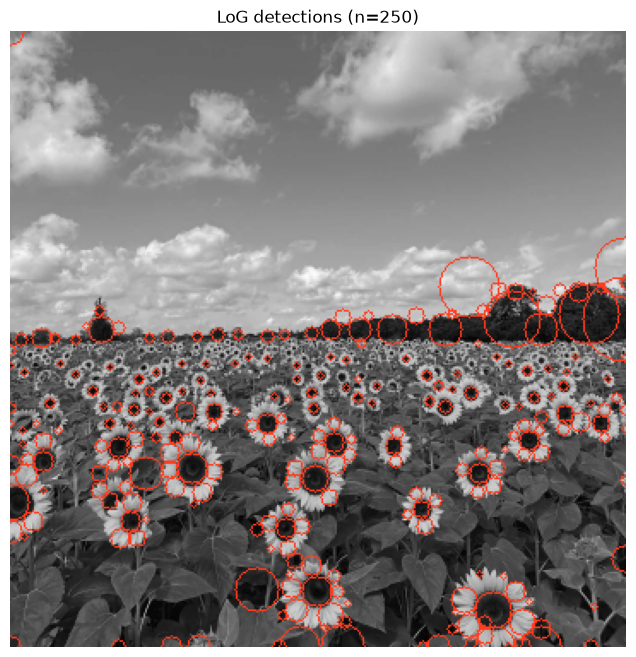

In [4]:
vis = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
for x, y, sigma, response in detections:
    radius = max(1, int(round(np.sqrt(2) * sigma)))
    cv2.circle(vis, (x, y), radius, (255, 60, 30), 1)

plt.figure(figsize=(14, 8))
plt.imshow(vis)
plt.title(f"LoG detections (n={len(detections)})")
plt.axis("off")


In [5]:
import pandas as pd

blob_table = pd.DataFrame([
    {"x": x, "y": y, "sigma": sigma,
     "estimated_radius_px": np.sqrt(2)*sigma, "response": response}
    for x, y, sigma, response in detections
])
blob_table = blob_table.sort_values("estimated_radius_px", ascending=False)
display(blob_table.head(20))


,x,y,sigma,estimated_radius_px,response
133,359,168,18.000000,25.455844,0.883945
91,338,165,13.016965,18.408768,0.990114
162,359,138,13.016965,18.408768,0.831794
222,268,149,13.016965,18.408768,0.722477
93,293,168,11.683926,16.523567,0.985734
41,194,359,9.413410,13.312572,1.267049
248,144,326,9.413410,13.312572,0.666128
113,310,359,8.449403,11.949261,0.938468
55,169,359,8.449403,11.949261,1.151558
43,283,359,8.449403,11.949261,1.237651
